# **1. Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn import metrics

sns.set_theme(style="whitegrid")

# **2. Data Loading**

In [2]:
#data = pd.read_csv('/content/drive/MyDrive/DTS/Data Mining/Data/Admission_Predict.csv')
data = pd.read_csv('https://raw.githubusercontent.com/data-insight-hub92/data-mining/refs/heads/main/datasets/Admission_Predict.csv')
data.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Chance of Admit
0,337,118,4,4.5,4.5,9.65,0.92
1,324,107,4,4.0,4.5,8.87,0.76
2,316,104,3,3.0,3.5,8.00,0.72
3,322,110,3,3.5,2.5,8.67,0.80
4,314,103,2,2.0,3.0,8.21,0.65


# **3. Data Inspection**

In [3]:
# Ukuran dataset: jumlah baris dan kolom
print("Dataset shape:", data.shape)

# Informasi tipe data dan jumlah nilai non-null
data.info()

Dataset shape: (400, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GRE Score          400 non-null    int64  
 1   TOEFL Score        400 non-null    int64  
 2   University Rating  400 non-null    int64  
 3   SOP                400 non-null    float64
 4   LOR                400 non-null    float64
 5   CGPA               400 non-null    float64
 6   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(3)
memory usage: 22.0 KB


In [4]:
# Statistik deskriptif untuk kolom numerik
data.describe().T

,count,mean,std,min,25%,50%,75%,max
GRE Score,400.0,316.807500,11.473646,290.00,308.00,317.00,325.0000,340.00
TOEFL Score,400.0,107.410000,6.069514,92.00,103.00,107.00,112.0000,120.00
University Rating,400.0,3.087500,1.143728,1.00,2.00,3.00,4.0000,5.00
SOP,400.0,3.400000,1.006869,1.00,2.50,3.50,4.0000,5.00
LOR,400.0,3.452500,0.898478,1.00,3.00,3.50,4.0000,5.00
CGPA,400.0,8.598925,0.596317,6.80,8.17,8.61,9.0625,9.92
Chance of Admit,400.0,0.724350,0.142609,0.34,0.64,0.73,0.8300,0.97


In [5]:
# Memeriksa missing values
data.isnull().sum()

,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Chance of Admit,0


In [6]:
# Memeriksa jumlah baris duplikat
print("Jumlah baris duplikat:", data.duplicated().sum())

Jumlah baris duplikat: 0


# **4. Define Features and Target**

In [7]:
# Strip any trailing whitespaces from the column names to avoid KeyErrors
data.columns = data.columns.str.strip()

feature_columns = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA']
X = data[feature_columns]
y = data['Chance of Admit']

# **5. Train-Test Split**

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# **6. Exploratory Data Analysis (Training Data)**

**6.1 Pairplot: Distribusi dan Hubungan antar-Variabel**

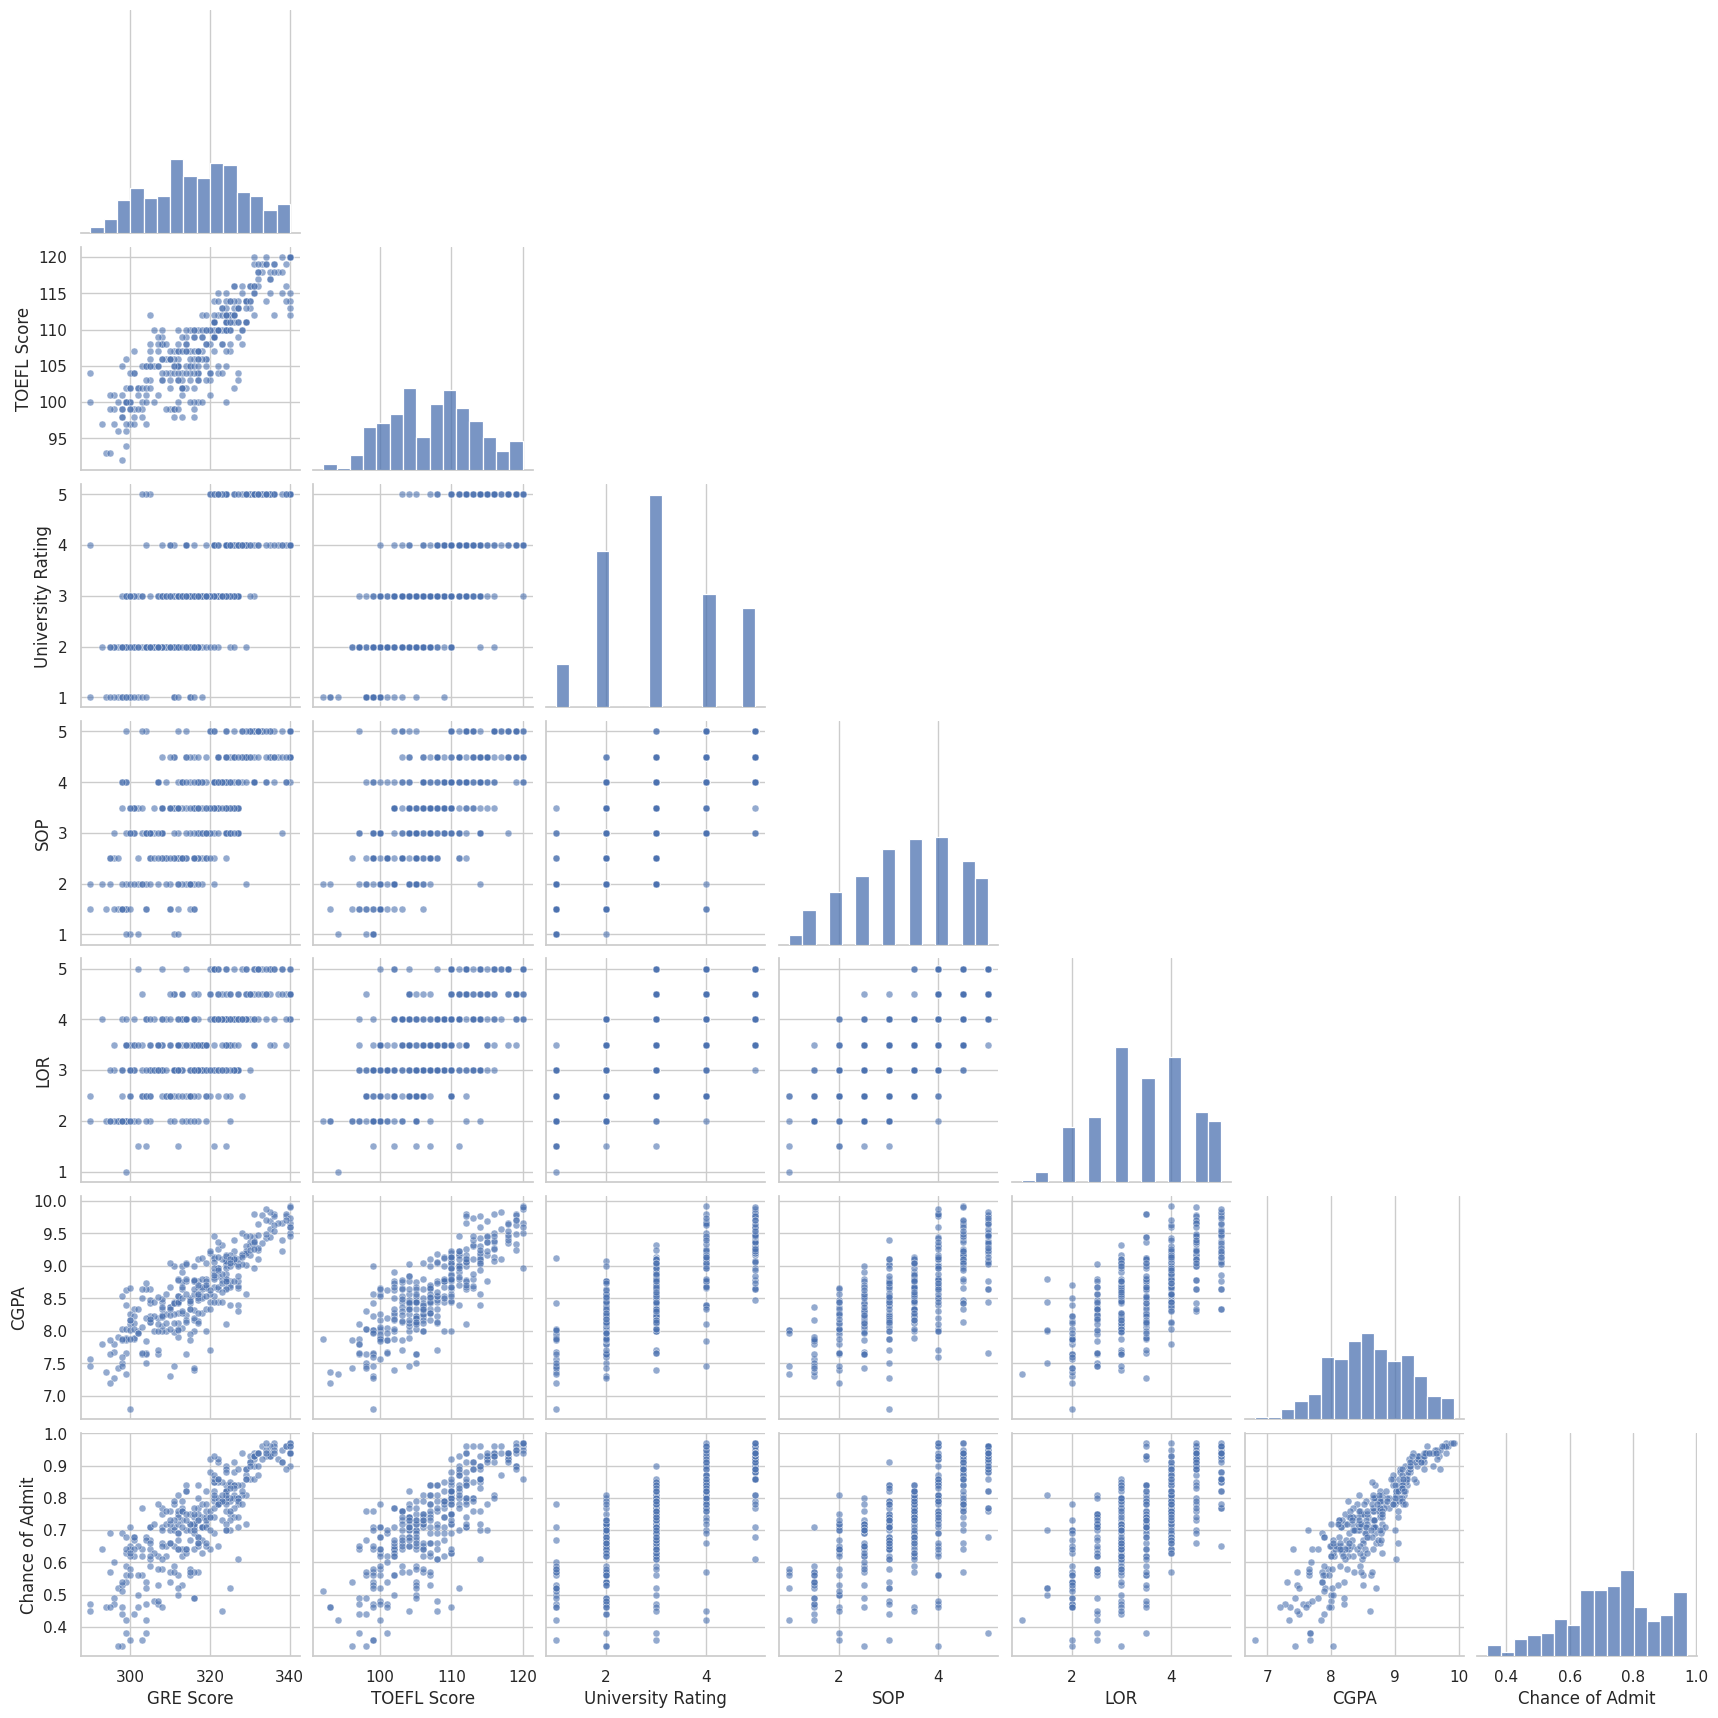

In [9]:
train_data = X_train.copy()
train_data['Chance of Admit'] = y_train

sns.pairplot(
    train_data,
    diag_kind='hist',
    corner=True,
    plot_kws={'alpha': 0.6, 's': 25},
    diag_kws={'bins': 15}
)

plt.show()

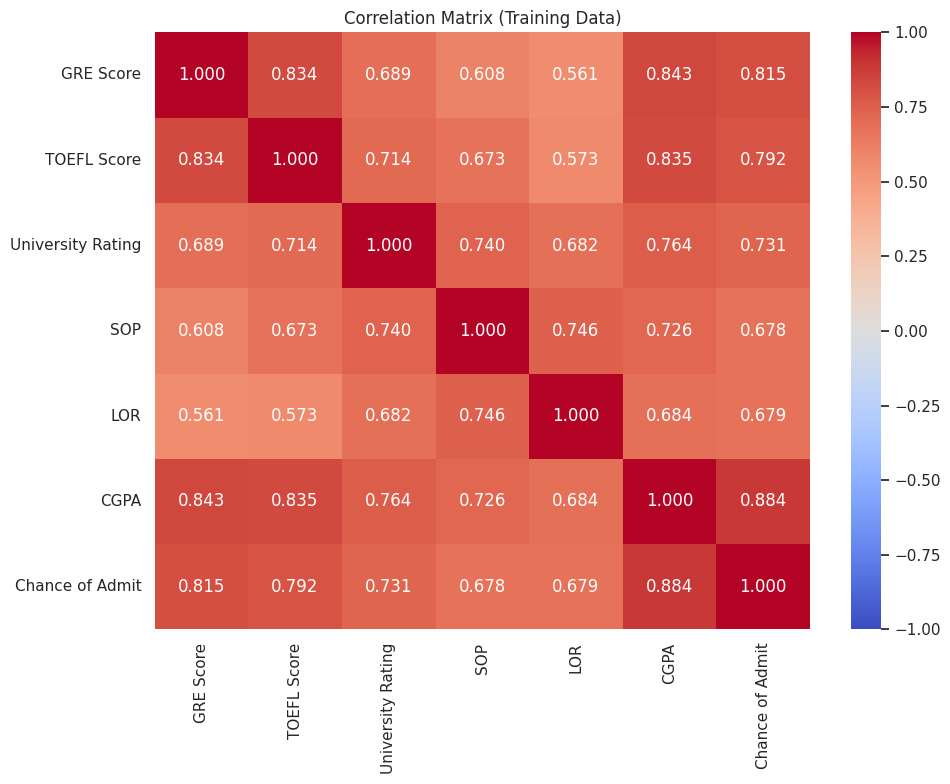

In [10]:
correlation_matrix = train_data.corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1)
plt.title('Correlation Matrix (Training Data)')
plt.tight_layout()
plt.show()

**6.2 Pemeriksaan Outlier pada Features**

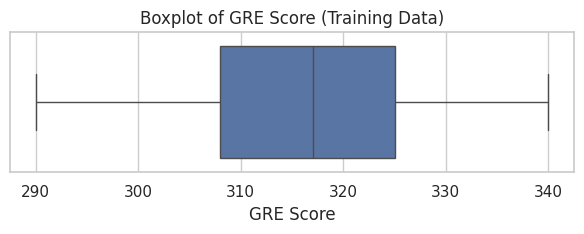

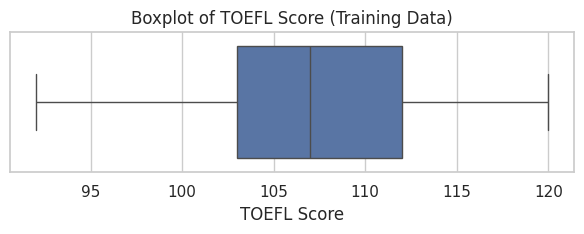

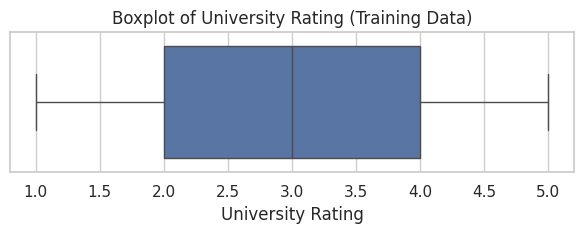

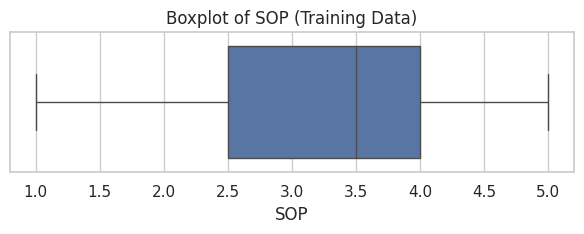

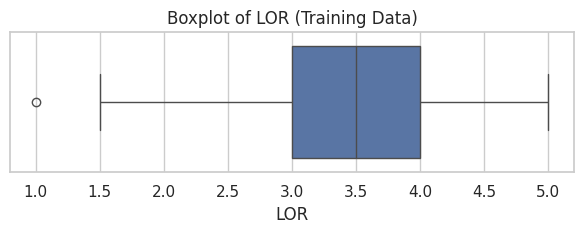

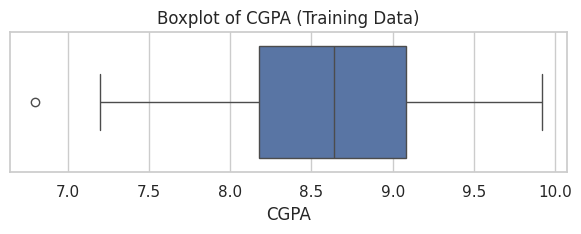

In [11]:
for column in X_train.columns:
    plt.figure(figsize=(6, 2.5))
    sns.boxplot(x=X_train[column])
    plt.title(f'Boxplot of {column} (Training Data)')
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

# **7. Model Building**

In [12]:
lr = LinearRegression()
lr.fit(X_train, y_train)
print(lr)

LinearRegression()


In [13]:
intercept = lr.intercept_
coefficient = lr.coef_

print("Intercept:", intercept)
print("Coefficient (TOEFL Score):", coefficient)

Intercept: -1.4458899929244335
Coefficient (TOEFL Score): [ 0.00252475  0.00194107  0.00703089 -0.00425489  0.02269074  0.12512472]


# **8. Prediction**

In [14]:
y_pred = lr.predict(X_test)

prediction_results = pd.DataFrame({'Actual': y_test.to_numpy(), 'Predicted': y_pred})
prediction_results.head(10)

,Actual,Predicted
0,0.71,0.708818
1,0.70,0.702627
2,0.79,0.772407
3,0.73,0.622051
4,0.72,0.735828
5,0.48,0.611245
6,0.77,0.717143
7,0.71,0.652926
8,0.90,0.866874
9,0.94,0.918013


# **9. Model Evaluation**

In [15]:
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
r2 = metrics.r2_score(y_test, y_pred)

In [16]:
print('Mean Absolute Error: {:.4f}%'.format(mae))
print('Mean Squared Error: {:.4f}%'.format(mse))
print('Root Mean Squared Error: {:.4f}%'.format(rmse))
print('R-Squared: {:.4f}%'.format(r2*100))
print('Mean Absolute Percentage Error (MAPE): {:.2f}%'.format(mape))

Mean Absolute Error: 0.0499%
Mean Squared Error: 0.0049%
Root Mean Squared Error: 0.0700%
R-Squared: 73.0208%
Mean Absolute Percentage Error (MAPE): 8.05%
